# PCL Detection - Ablation Study & Local Evaluation

This notebook systematically evaluates the contribution of each component of the BestModel.

In [ ]:
import re
import os
import json
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    precision_recall_curve, average_precision_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
matplotlib.rcParams['figure.dpi'] = 120
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, set_seed, EarlyStoppingCallback
)

GLOBAL_SEED = 42
set_seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

./venv_nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [ ]:
CFG = {'llrd_decay' : 0.95, 'focal_alpha' : 0.8, 'focal_gamma' : 2.0, 'seeds' : [42, 7, 21], 'checkpoint_dir' : './checkpoints','ablation_dir'   : './ablation_checkpoints',}
os.makedirs(CFG['ablation_dir'], exist_ok=True)

## Data loading 

In [ ]:
def clean_text(text):
    text = re.sub(r'@@\d+', '', str(text))
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def build_prompt(row):
    return f"Context: {row['keyword']} in {row['country_code']}. Statement: {clean_text(row['text'])}"

def load_data():
    df_raw = pd.read_csv(
        './NLPLabs-2024/Dont_Patronize_Me_Trainingset/dontpatronizeme_pcl.tsv',
        sep='\t', skiprows=4, header=None,
        names=['par_id', 'art_id', 'keyword', 'country_code', 'text', 'label'],
        quoting=3
    )
    df_raw.dropna(subset=['text', 'label'], inplace=True)
    df_raw['label_binary'] = (pd.to_numeric(df_raw['label'], errors='coerce') >= 2).astype(int)
    df_raw.dropna(subset=['label_binary'], inplace=True)
    df_raw['processed_text'] = df_raw.apply(build_prompt, axis=1)
    train_ids = pd.read_csv('./dontpatronizeme/semeval-2022/practice splits/train_semeval_parids-labels.csv')
    dev_ids   = pd.read_csv('./dontpatronizeme/semeval-2022/practice splits/dev_semeval_parids-labels.csv')
    df_train    = train_ids[['par_id']].merge(df_raw, on='par_id', how='inner')
    df_dev_full = dev_ids[['par_id']].merge(df_raw, on='par_id', how='inner')
    df_dev, df_test = train_test_split(
        df_dev_full, test_size=0.5,
        stratify=df_dev_full['label_binary'], random_state=GLOBAL_SEED
    )
    print(f'Train: {len(df_train)} | Dev: {len(df_dev)} | Test: {len(df_test)}')
    return df_train, df_dev, df_test

df_train, df_dev, df_test = load_data()


Train: 8375 | Dev: 1046 | Test: 1047


## Tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained('roberta-large')

class PCLDataset(Dataset):
    def __init__(self, texts, labels, tokenizer):
        self.texts     = texts.astype(str).tolist()
        self.labels    = labels.tolist()
        self.tokenizer = tokenizer

    def __len__(self): return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=512,
            return_tensors='pt'
        )
        return {
            'input_ids'     : enc['input_ids'].flatten(),
            'attention_mask': enc['attention_mask'].flatten(),
            'labels'        : torch.tensor(self.labels[idx], dtype=torch.long)
        }

def make_datasets(df_tr, df_dv, df_te):
    return (
        PCLDataset(df_tr['processed_text'], df_tr['label_binary'], tokenizer),
        PCLDataset(df_dv['processed_text'], df_dv['label_binary'], tokenizer),
        PCLDataset(df_te['processed_text'], df_te['label_binary'], tokenizer),
    )

train_ds, dev_ds, test_ds = make_datasets(df_train, df_dev, df_test)
y_test = df_test['label_binary'].values

## Focal Loss 


In [ ]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    def forward(self, logits, labels):
        probs      = F.softmax(logits, dim=-1)
        true_probs = probs.gather(1, labels.view(-1, 1))
        focal_term = (1 - true_probs) ** self.gamma
        ce_loss    = F.cross_entropy(logits, labels, reduction='none')
        return (self.alpha * focal_term.view(-1) * ce_loss).mean()


## Metrics


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = F.softmax(torch.from_numpy(logits), dim=-1)[:, 1].numpy()
    auprc = float(average_precision_score(labels, probs))
    prec, rec, thresh = precision_recall_curve(labels, probs)
    f1s    = (2 * prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    best_i = int(np.argmax(f1s))
    return {'auprc': auprc, 'ceiling_f1': float(f1s[best_i]), 'best_thresh': float(thresh[best_i])}

def optimal_threshold(probs, labels):
    prec, rec, thresh = precision_recall_curve(labels, probs)
    f1s    = (2 * prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-10)
    best_i = int(np.argmax(f1s))
    return float(thresh[best_i]), float(f1s[best_i])

def get_probs_from_model(model, ds):
    model.to(DEVICE)
    model.eval()
    loader = torch.utils.data.DataLoader(ds, batch_size=16)
    all_probs = []
    with torch.no_grad():
        for batch in loader:
            logits = model(
                input_ids=batch['input_ids'].to(DEVICE),
                attention_mask=batch['attention_mask'].to(DEVICE)
            ).logits
            all_probs.append(F.softmax(logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(all_probs)


## Trainer

In [ ]:
class FlexTrainer(Trainer):
    def __init__(self, *args, use_llrd=False, use_focal=False, **kwargs):
        super().__init__(*args, **kwargs)
        self.use_llrd  = use_llrd
        self.use_focal = use_focal

    def create_optimizer(self):
        if not self.use_llrd or self.optimizer is not None:
            return super().create_optimizer()
        lr, wd, decay = self.args.learning_rate, self.args.weight_decay, CFG['llrd_decay']
        no_decay = ['bias', 'LayerNorm.weight', 'LayerNorm.bias']
        named_params = list(self.model.named_parameters())
        def make_group(params, lr_val, apply_wd):
            return {'params': params, 'lr': lr_val, 'weight_decay': wd if apply_wd else 0.0}
        groups = []
        head_nd = [p for n,p in named_params if 'classifier' in n and not any(nd in n for nd in no_decay)]
        head_d  = [p for n,p in named_params if 'classifier' in n and     any(nd in n for nd in no_decay)]
        if head_nd: groups.append(make_group(head_nd, lr, True))
        if head_d:  groups.append(make_group(head_d,  lr, False))
        current_lr = lr
        for layer in reversed(list(self.model.roberta.encoder.layer)):
            current_lr *= decay
            nd = [p for n,p in layer.named_parameters() if not any(x in n for x in no_decay)]
            d  = [p for n,p in layer.named_parameters() if     any(x in n for x in no_decay)]
            if nd: groups.append(make_group(nd, current_lr, True))
            if d:  groups.append(make_group(d,  current_lr, False))
        current_lr *= decay
        emb_nd = [p for n,p in self.model.roberta.embeddings.named_parameters() if not any(x in n for x in no_decay)]
        emb_d  = [p for n,p in self.model.roberta.embeddings.named_parameters() if     any(x in n for x in no_decay)]
        if emb_nd: groups.append(make_group(emb_nd, current_lr, True))
        if emb_d:  groups.append(make_group(emb_d,  current_lr, False))
        self.optimizer = AdamW(groups, lr=lr)
        return self.optimizer

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels  = inputs.get('labels')
        outputs = model(**inputs)
        if self.use_focal:
            focal_fn = FocalLoss(alpha=CFG['focal_alpha'], gamma=CFG['focal_gamma'])
            loss = focal_fn(outputs.get('logits'), labels)
        else:
            loss = F.cross_entropy(outputs.get('logits'), labels)
        return (loss, outputs) if return_outputs else loss


def train_baseline():
    RUN_DIR = './ablation_checkpoints/A_baseline'
    os.makedirs(RUN_DIR, exist_ok=True)

    existing = sorted([d for d in os.listdir(RUN_DIR)
                       if d.startswith('checkpoint-') and os.path.isdir(os.path.join(RUN_DIR, d))])
    if existing:
        best_ckpt = None
        for ckpt in existing:
            sp = os.path.join(RUN_DIR, ckpt, 'trainer_state.json')
            if os.path.exists(sp):
                with open(sp) as f: state = json.load(f)
                if state.get('best_model_checkpoint'): best_ckpt = state['best_model_checkpoint']
        load_path = best_ckpt or os.path.join(RUN_DIR, existing[-1])
        print(f'  [A_baseline] Loading from {load_path}')
        model = AutoModelForSequenceClassification.from_pretrained(load_path)
    else:
        set_seed(42)
        model = AutoModelForSequenceClassification.from_pretrained('roberta-large', num_labels=2)
        trainer = Trainer(
            model        = model,
            args         = TrainingArguments(
                output_dir                  = RUN_DIR,
                num_train_epochs            = 3,
                per_device_train_batch_size = 8,
                gradient_accumulation_steps = 1,
                learning_rate               = 2e-5,
                lr_scheduler_type           = 'linear',
                fp16                        = True,
                eval_strategy               = 'epoch',
                save_strategy               = 'epoch',
                load_best_model_at_end      = True,
                metric_for_best_model       = 'eval_loss',
                greater_is_better           = False,
                save_total_limit            = 2,
                report_to                   = 'none',
                seed                        = 42,
            ),
            train_dataset   = train_ds,
            eval_dataset    = dev_ds,
            compute_metrics = compute_metrics,
        )
        trainer.train()
        print(f'  [A_baseline] Best ckpt: {trainer.state.best_model_checkpoint}')

    dev_probs  = get_probs_from_model(model, dev_ds)
    test_probs = get_probs_from_model(model, test_ds)

    t, dev_f1 = optimal_threshold(dev_probs, df_dev['label_binary'].values)
    dev_auprc  = average_precision_score(df_dev['label_binary'], dev_probs)

    test_preds = (test_probs >= t).astype(int)
    test_f1    = f1_score(y_test, test_preds)
    test_p     = precision_score(y_test, test_preds, zero_division=0)
    test_r     = recall_score(y_test, test_preds)
    test_auprc = average_precision_score(y_test, test_probs)

    print(f'  [A_baseline] Dev  → AUPRC={dev_auprc:.4f} | F1={dev_f1:.4f} @ t={t:.4f}')
    print(f'  [A_baseline] Test → AUPRC={test_auprc:.4f} | F1={test_f1:.4f} | P={test_p:.4f} | R={test_r:.4f}')

    return dev_probs, test_probs


def train_one_run(run_name, use_llrd, use_focal, seed=42):
    RUN_DIR = os.path.join(CFG['ablation_dir'], run_name)
    os.makedirs(RUN_DIR, exist_ok=True)

    existing = sorted([d for d in os.listdir(RUN_DIR)
                       if d.startswith('checkpoint-') and os.path.isdir(os.path.join(RUN_DIR, d))])
    if existing:
        best_ckpt = None
        for ckpt in existing:
            sp = os.path.join(RUN_DIR, ckpt, 'trainer_state.json')
            if os.path.exists(sp):
                with open(sp) as f: state = json.load(f)
                if state.get('best_model_checkpoint'): best_ckpt = state['best_model_checkpoint']
        load_path = best_ckpt or os.path.join(RUN_DIR, existing[-1])
        print(f'  [{run_name}] Loading from {load_path}')
        model = AutoModelForSequenceClassification.from_pretrained(load_path)
    else:
        set_seed(seed)
        model = AutoModelForSequenceClassification.from_pretrained('roberta-large', num_labels=2)
        trainer = FlexTrainer(
            model        = model,
            args         = TrainingArguments(
                output_dir                  = RUN_DIR,
                num_train_epochs            = 6,
                per_device_train_batch_size = 4,
                gradient_accumulation_steps = 2,
                learning_rate               = 1e-5,
                weight_decay                = 0.01,
                warmup_ratio                = 0.1,
                lr_scheduler_type           = 'cosine',
                fp16                        = True,
                eval_strategy               = 'epoch',
                save_strategy               = 'epoch',
                load_best_model_at_end      = True,
                metric_for_best_model       = 'auprc',
                greater_is_better           = True,
                save_total_limit            = 2,
                report_to                   = 'none',
                seed                        = seed,
                logging_steps               = 50,
            ),
            train_dataset   = train_ds,
            eval_dataset    = dev_ds,
            compute_metrics = compute_metrics,
            use_llrd        = use_llrd,
            use_focal       = use_focal,
            callbacks       = [EarlyStoppingCallback(early_stopping_patience=2)],
        )
        trainer.train()
        print(f'  [{run_name}] Best ckpt: {trainer.state.best_model_checkpoint}')

    dev_probs  = get_probs_from_model(model, dev_ds)
    test_probs = get_probs_from_model(model, test_ds)

    t, dev_f1 = optimal_threshold(dev_probs, df_dev['label_binary'].values)
    dev_auprc  = average_precision_score(df_dev['label_binary'], dev_probs)

    test_preds = (test_probs >= t).astype(int)
    test_f1    = f1_score(y_test, test_preds)
    test_p     = precision_score(y_test, test_preds, zero_division=0)
    test_r     = recall_score(y_test, test_preds)
    test_auprc = average_precision_score(y_test, test_probs)

    print(f'  [{run_name}] Dev  → AUPRC={dev_auprc:.4f} | F1={dev_f1:.4f} @ t={t:.4f}')
    print(f'  [{run_name}] Test → AUPRC={test_auprc:.4f} | F1={test_f1:.4f} | P={test_p:.4f} | R={test_r:.4f}')

    return dev_probs, test_probs

In [ ]:
import gc
import torch
gc.collect()
torch.cuda.empty_cache()
print(f'Free VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB total')

Free VRAM: 16.7 GB total


## Baseline

In [ ]:
print('=== Run A: Baseline ===')
dev_A, test_A = train_baseline()

=== Run A: Baseline ===


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 9103.25it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Auprc,Ceiling F1,Best Thresh
1,0.306697,0.256255,0.572856,0.558140,0.042404
2,0.229546,0.352203,0.626627,0.580357,0.016882
3,0.093368,0.425013,0.608737,0.594595,0.019033


[... earlier log lines omitted ...]


  [A_baseline] Best ckpt: ./ablation_checkpoints/A_baseline/checkpoint-1047
  [A_baseline] Dev  → AUPRC=0.5710 | F1=0.5581 @ t=0.0426
  [A_baseline] Test → AUPRC=0.5558 | F1=0.5471 | P=0.4959 | R=0.6100


## Focal Loss only

In [ ]:
print('\n=== Run B: Focal Loss only ===')
dev_B, test_B = train_one_run('B_focal_only', use_llrd=False, use_focal=True)


=== Run B: Focal Loss only ===


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 9463.95it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be rem

Epoch,Training Loss,Validation Loss,Auprc,Ceiling F1,Best Thresh
1,0.137800,0.050819,0.585489,0.588235,0.368264
2,0.126483,0.080859,0.613951,0.608295,0.160990
3,0.057835,0.079343,0.613041,0.613333,0.206294
4,0.014510,0.113170,0.631847,0.638095,0.140867
5,0.009678,0.129334,0.634464,0.645161,0.229363
6,0.000039,0.142528,0.629545,0.635417,0.161916


[... earlier log lines omitted ...]


  [B_focal_only] Best ckpt: ./ablation_checkpoints/B_focal_only/checkpoint-5235
  [A_baseline] Dev  → AUPRC=0.6347 | F1=0.6452 @ t=0.2292
  [A_baseline] Test → AUPRC=0.5769 | F1=0.5473 | P=0.5446 | R=0.5500


## LLRD only

In [ ]:
print('\n=== Run C: LLRD only ===')
dev_C, test_C = train_one_run('C_llrd_only',  use_llrd=True,  use_focal=False)


=== Run C: LLRD only ===


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 9625.64it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be rem

Epoch,Training Loss,Validation Loss,Auprc,Ceiling F1,Best Thresh
1,0.609732,0.289429,0.564292,0.559140,0.096791
2,0.622709,0.306646,0.636081,0.614634,0.020274
3,0.350004,0.314544,0.629080,0.652174,0.215598
4,0.233891,0.360521,0.661139,0.631579,0.194062
5,0.203309,0.445661,0.668605,0.631579,0.006864
6,0.000523,0.469882,0.667993,0.628019,0.008046


[... earlier log lines omitted ...]


  [C_llrd_only] Best ckpt: ./ablation_checkpoints/C_llrd_only/checkpoint-5235
  [C_llrd_only] Dev  → AUPRC=0.6686 | F1=0.6316 @ t=0.0069
  [C_llrd_only] Test → AUPRC=0.6666 | F1=0.5797 | P=0.5607 | R=0.6000


## LLRD + Focal

In [ ]:
print('\n=== Run D: LLRD + Focal (single seed) ===')
dev_D, test_D = train_one_run('D_llrd_focal', use_llrd=True,  use_focal=True)


=== Run D: LLRD + Focal (single seed) ===


Loading weights: 100%|██████████| 389/389 [00:00<00:00, 10096.50it/s]
RobertaForSequenceClassification LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.bias        | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be re

Epoch,Training Loss,Validation Loss,Auprc,Ceiling F1,Best Thresh
1,0.103916,0.067566,0.573871,0.583851,0.370353
2,0.139384,0.065159,0.640283,0.617021,0.326620
3,0.073476,0.076616,0.645836,0.628272,0.315960
4,0.033260,0.096437,0.660282,0.660550,0.134833
5,0.009856,0.115928,0.676368,0.666667,0.423875
6,0.000107,0.118833,0.666827,0.663366,0.246760


[... earlier log lines omitted ...]


  [D_llrd_focal] Best ckpt: ./ablation_checkpoints/D_llrd_focal/checkpoint-5235
  [D_llrd_focal] Dev  → AUPRC=0.6760 | F1=0.6667 @ t=0.4241
  [D_llrd_focal] Test → AUPRC=0.6503 | F1=0.5941 | P=0.5882 | R=0.6000


In [ ]:
best_dev_probs_list  = []
best_test_probs_list = []

for seed in CFG['seeds']:
    run_dir = os.path.join(CFG['checkpoint_dir'], f'seed_{seed}')
    existing = sorted([d for d in os.listdir(run_dir)
                       if d.startswith('checkpoint-') and os.path.isdir(os.path.join(run_dir, d))])
    best_ckpt = None
    for ckpt in existing:
        sp = os.path.join(run_dir, ckpt, 'trainer_state.json')
        if os.path.exists(sp):
            with open(sp) as f: state = json.load(f)
            if state.get('best_model_checkpoint'): best_ckpt = state['best_model_checkpoint']
    load_path = best_ckpt or os.path.join(run_dir, existing[-1])
    print(f'Loading BestModel seed={seed} from {load_path}')
    m = AutoModelForSequenceClassification.from_pretrained(load_path)
    best_dev_probs_list.append(get_probs_from_model(m, dev_ds))
    best_test_probs_list.append(get_probs_from_model(m, test_ds))

dev_E  = np.stack(best_dev_probs_list,  axis=0).mean(axis=0)
test_E = np.stack(best_test_probs_list, axis=0).mean(axis=0)
print('BestModel ensemble probs loaded.')


Loading BestModel seed=42 from ./checkpoints/seed_42/checkpoint-4188


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9672.06it/s]


Loading BestModel seed=7 from ./checkpoints/seed_7/checkpoint-3141


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 9994.79it/s]


Loading BestModel seed=21 from ./checkpoints/seed_21/checkpoint-5235


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 10594.81it/s]


BestModel ensemble probs loaded.


## Best Model

In [ ]:
dev_E  = np.stack(best_dev_probs_list,  axis=0).mean(axis=0)
test_E = np.stack(best_test_probs_list, axis=0).mean(axis=0)

t, dev_f1 = optimal_threshold(dev_E, df_dev['label_binary'].values)
dev_auprc  = average_precision_score(df_dev['label_binary'], dev_E)

test_preds_E = (test_E >= t).astype(int)
test_f1    = f1_score(y_test, test_preds_E)
test_p     = precision_score(y_test, test_preds_E, zero_division=0)
test_r     = recall_score(y_test, test_preds_E)
test_auprc = average_precision_score(y_test, test_E)

print(f'  [E_bestmodel] Dev  → AUPRC={dev_auprc:.4f} | F1={dev_f1:.4f} @ t={t:.4f}')
print(f'  [E_bestmodel] Test → AUPRC={test_auprc:.4f} | F1={test_f1:.4f} | P={test_p:.4f} | R={test_r:.4f}')

  [E_bestmodel] Dev  → AUPRC=0.6949 | F1=0.6700 @ t=0.3345
  [E_bestmodel] Test → AUPRC=0.7003 | F1=0.6176 | P=0.6058 | R=0.6300


## Ablation Results Table

In [ ]:
runs = [
    ('A — Baseline (CE, flat LR)',          False, False, False, dev_A,  test_A),
    ('B — Focal Loss only',                 False, True,  False, dev_B,  test_B),
    ('C — LLRD only',                       True,  False, False, dev_C,  test_C),
    ('D — LLRD + Focal (single seed)',      True,  True,  False, dev_D,  test_D),
    ('E — BestModel (LLRD+Focal+Ensemble)', True,  True,  True,  dev_E,  test_E),
]

rows = []
for name, llrd, focal, ens, dev_p, test_p in runs:
    t, _ = optimal_threshold(dev_p, df_dev['label_binary'].values)
    preds = (test_p >= t).astype(int)
    rows.append({
        'Model'      : name,
        'LLRD'       : '✓' if llrd  else '✗',
        'Focal'      : '✓' if focal else '✗',
        'Ensemble'   : '✓' if ens   else '✗',
        'Dev AUPRC'  : round(average_precision_score(df_dev['label_binary'], dev_p), 4),
        'Test AUPRC' : round(average_precision_score(y_test, test_p), 4),
        'Test F1'    : round(f1_score(y_test, preds), 4),
        'Precision'  : round(precision_score(y_test, preds, zero_division=0), 4),
        'Recall'     : round(recall_score(y_test, preds), 4),
        'Threshold'  : round(t, 4),
    })

ablation_df = pd.DataFrame(rows)
print(ablation_df.to_string(index=False))
ablation_df.to_csv('ablation_table.csv', index=False)
print('\nSaved: ablation_table.csv')


                              Model LLRD Focal Ensemble  Dev AUPRC  Test AUPRC  Test F1  Precision  Recall  Threshold
         A — Baseline (CE, flat LR)    ✗     ✗        ✗     0.5710      0.5558   0.5471     0.4959    0.61     0.0426
                B — Focal Loss only    ✗     ✓        ✗     0.6347      0.5769   0.5473     0.5446    0.55     0.2292
                      C — LLRD only    ✓     ✗        ✗     0.6686      0.6666   0.5797     0.5607    0.60     0.0069
     D — LLRD + Focal (single seed)    ✓     ✓        ✗     0.6760      0.6503   0.5941     0.5882    0.60     0.4241
E — BestModel (LLRD+Focal+Ensemble)    ✓     ✓        ✓     0.6949      0.7003   0.6176     0.6058    0.63     0.3345

Saved: ablation_table.csv


## Ablation Bar Chart

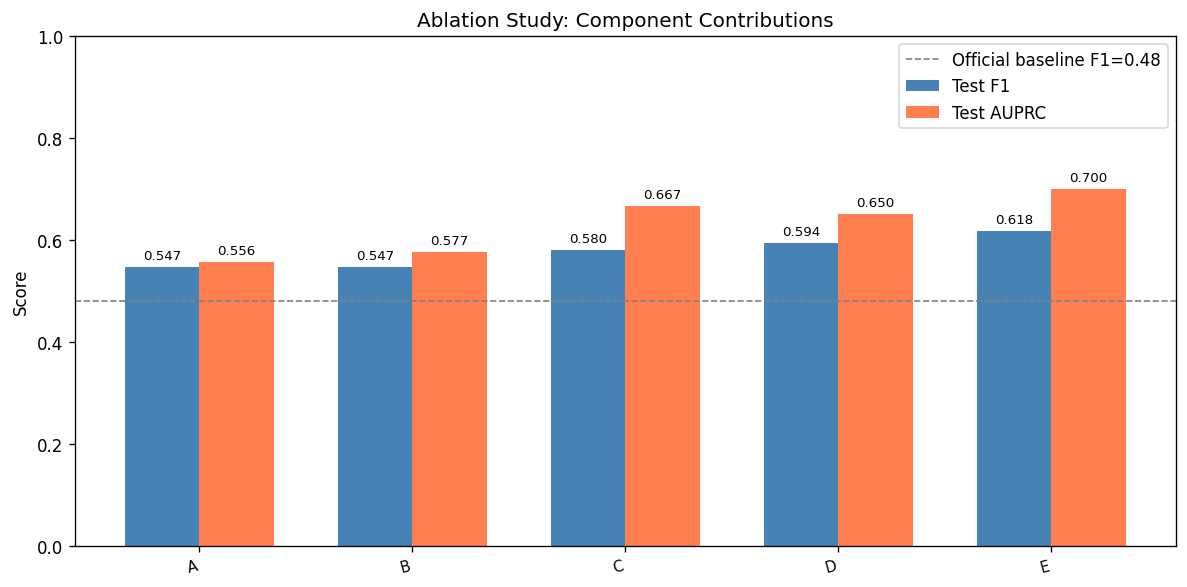

Saved: ablation_bar_chart.png


In [ ]:
labels_plot = [r['Model'].split('—')[0].strip() for r in rows]
f1_vals     = [r['Test F1']    for r in rows]
auprc_vals  = [r['Test AUPRC'] for r in rows]

x = np.arange(len(labels_plot))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, f1_vals,    width, label='Test F1',    color='steelblue')
bars2 = ax.bar(x + width/2, auprc_vals, width, label='Test AUPRC', color='coral')

ax.axhline(0.48, color='grey', linestyle='--', linewidth=1, label='Official baseline F1=0.48')
ax.set_xticks(x)
ax.set_xticklabels(labels_plot, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Ablation Study: Component Contributions')
ax.legend()
ax.set_ylim(0, 1)
for bar in bars1: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
for bar in bars2: ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('ablation_bar_chart.png', bbox_inches='tight')
plt.show()
print('Saved: ablation_bar_chart.png')


---
## Section 2 - Custom Metrics (Local Evaluation)
Precision-Recall curves and confusion matrices comparing the Baseline vs BestModel
on the internal test set.

## PR Curve: Baseline vs BestModel

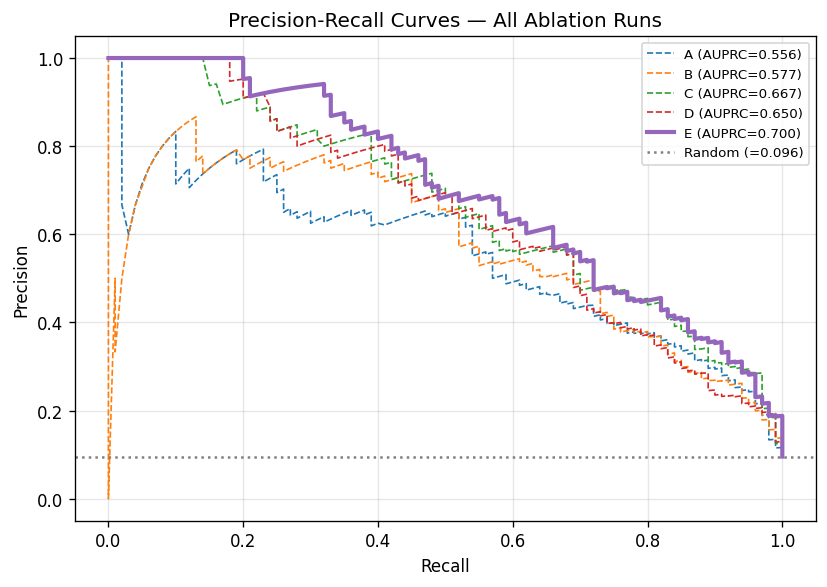

Saved: pr_curves_ablation.png


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

for name, _, _, _, dev_p, test_p in runs:
    prec_c, rec_c, _ = precision_recall_curve(y_test, test_p)
    auprc_c = average_precision_score(y_test, test_p)
    lw = 2.5 if 'BestModel' in name else 1.0
    ls = '-'  if 'BestModel' in name else '--'
    ax.plot(rec_c, prec_c, linewidth=lw, linestyle=ls,
            label=f"{name.split('—')[0].strip()} (AUPRC={auprc_c:.3f})")

pcl_prior = y_test.mean()
ax.axhline(pcl_prior, color='grey', linestyle=':', label=f'Random (={pcl_prior:.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — All Ablation Runs')
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('pr_curves_ablation.png', bbox_inches='tight')
plt.show()
print('Saved: pr_curves_ablation.png')


## Confusion Matrices: Baseline vs BestModel

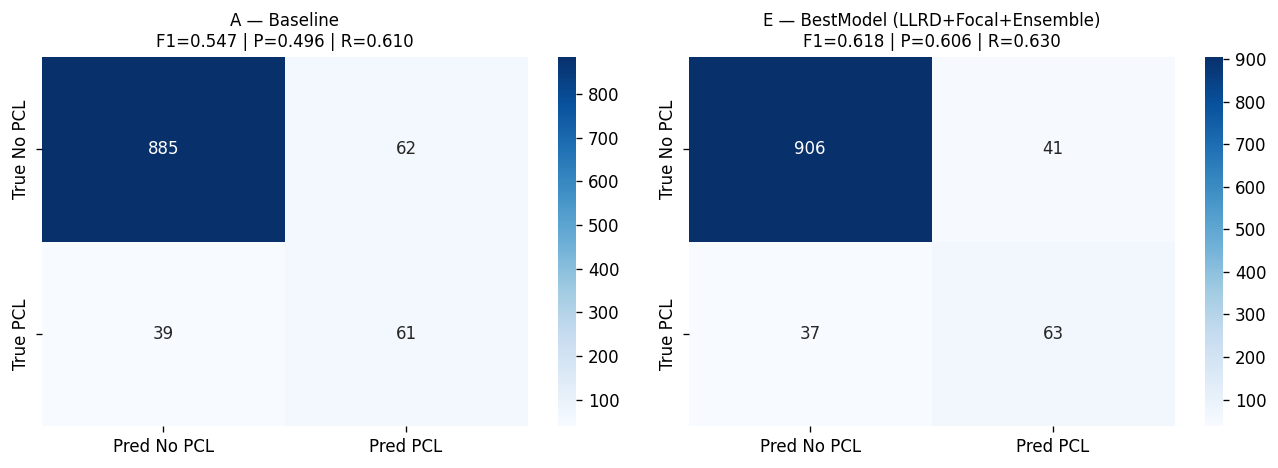

Saved: confusion_matrices.png


In [ ]:
t_A, _ = optimal_threshold(dev_A, df_dev['label_binary'].values)
t_E, _ = optimal_threshold(dev_E, df_dev['label_binary'].values)
preds_A = (test_A >= t_A).astype(int)
preds_E = (test_E >= t_E).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, preds, title in zip(
    axes,
    [preds_A, preds_E],
    ['A — Baseline', 'E — BestModel (LLRD+Focal+Ensemble)']
):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred No PCL','Pred PCL'],
                yticklabels=['True No PCL','True PCL'])
    f1_  = f1_score(y_test, preds)
    prec_ = precision_score(y_test, preds, zero_division=0)
    rec_  = recall_score(y_test, preds)
    ax.set_title(f'{title}\nF1={f1_:.3f} | P={prec_:.3f} | R={rec_:.3f}', fontsize=10)
plt.tight_layout()
plt.savefig('confusion_matrices.png', bbox_inches='tight')
plt.show()
print('Saved: confusion_matrices.png')


## Classification Reports

In [ ]:
print('=== Run A — Baseline ===')
print(classification_report(y_test, preds_A, target_names=['No PCL','PCL'], digits=4))
print()
print('=== Run E — BestModel ===')
print(classification_report(y_test, preds_E, target_names=['No PCL','PCL'], digits=4))


=== Run A — Baseline ===
              precision    recall  f1-score   support

      No PCL     0.9578    0.9345    0.9460       947
         PCL     0.4959    0.6100    0.5471       100

    accuracy                         0.9035      1047
   macro avg     0.7269    0.7723    0.7466      1047
weighted avg     0.9137    0.9035    0.9079      1047


=== Run E — BestModel ===
              precision    recall  f1-score   support

      No PCL     0.9608    0.9567    0.9587       947
         PCL     0.6058    0.6300    0.6176       100

    accuracy                         0.9255      1047
   macro avg     0.7833    0.7934    0.7882      1047
weighted avg     0.9269    0.9255    0.9262      1047



---
## Section 3 — Error Analysis
Manually inspecting where the BestModel fails and comparing with the Baseline.
The four quadrants of interest are:
- **(a)** Both correct — what does the model learn well?
- **(b)** Both wrong — hard examples neither model can solve
- **(c)** BestModel correct, Baseline wrong — where our approach helps
- **(d)** Baseline correct, BestModel wrong — regressions introduced

In [ ]:
# ── Error Analysis ───────────────────────────────────────────────────────────
df_ea = df_test.copy().reset_index(drop=True)
df_ea['gold']       = y_test
df_ea['pred_A']     = preds_A
df_ea['pred_E']     = preds_E
df_ea['prob_A']     = test_A
df_ea['prob_E']     = test_E

both_correct   = df_ea[(df_ea['pred_A']==df_ea['gold']) & (df_ea['pred_E']==df_ea['gold'])]
both_wrong     = df_ea[(df_ea['pred_A']!=df_ea['gold']) & (df_ea['pred_E']!=df_ea['gold'])]
best_only_right= df_ea[(df_ea['pred_A']!=df_ea['gold']) & (df_ea['pred_E']==df_ea['gold'])]
base_only_right= df_ea[(df_ea['pred_A']==df_ea['gold']) & (df_ea['pred_E']!=df_ea['gold'])]

print(f'(a) Both correct          : {len(both_correct)}')
print(f'(b) Both wrong            : {len(both_wrong)}')
print(f'(c) BestModel only right  : {len(best_only_right)}')
print(f'(d) Baseline only right   : {len(base_only_right)}')

def show_examples(df, label, n=3):
    print(f'\n--- {label} (top {n}) ---')
    subset = df[df['gold']==1].sort_values('prob_E', ascending=False).head(n)
    if len(subset) == 0:
        subset = df.sort_values('prob_E', ascending=False).head(n)
    for _, row in subset.iterrows():
        print(f"  gold={row['gold']} | pred_A={row['pred_A']} | pred_E={row['pred_E']} "
              f"| prob_E={row['prob_E']:.3f} | kw={row['keyword']}")
        print(f"  {row['text'][:150]}")
        print()

show_examples(both_wrong,      '(b) Both wrong — hard cases')
show_examples(best_only_right, '(c) BestModel fixes Baseline errors')
show_examples(base_only_right, '(d) BestModel regressions')

both_wrong.to_csv('error_both_wrong.csv', index=False)
best_only_right.to_csv('error_best_fixes.csv', index=False)
base_only_right.to_csv('error_regressions.csv', index=False)
print('Saved: error_both_wrong.csv, error_best_fixes.csv, error_regressions.csv')


(a) Both correct          : 923
(b) Both wrong            : 55
(c) BestModel only right  : 46
(d) Baseline only right   : 23

--- (b) Both wrong — hard cases (top 3) ---
  gold=1 | pred_A=0 | pred_E=0 | prob_E=0.322 | kw=poor-families
  10:41am - Parents of children who died must get compensation , free medicine must be provided to poor families across UP : Ram Gopal Yadav

  gold=1 | pred_A=0 | pred_E=0 | prob_E=0.302 | kw=poor-families
  However , this success story is not uncommon . It often happens that people from poor families have more perseverance to fight tooth an nail in busine

  gold=1 | pred_A=0 | pred_E=0 | prob_E=0.267 | kw=poor-families
  I now know why Mike Redmond is proposing a school lunch program . This news about 1/4 of all kids coming from poor families with not much food is an e


--- (c) BestModel fixes Baseline errors (top 3) ---
  gold=1 | pred_A=0 | pred_E=1 | prob_E=0.914 | kw=vulnerable
  The Turkish Ambassador to Tanzania Ali Davutoglu has called on civil

## False Positive / False Negative Analysis for BestModel 

In [ ]:
fn_E = df_ea[(df_ea['gold']==1) & (df_ea['pred_E']==0)].sort_values('prob_E', ascending=False)
fp_E = df_ea[(df_ea['gold']==0) & (df_ea['pred_E']==1)].sort_values('prob_E', ascending=False)

print(f'BestModel False Negatives (PCL missed): {len(fn_E)}')
print(f'BestModel False Positives (wrongly flagged): {len(fp_E)}')

print('\n--- Top 3 False Negatives (highest prob but still missed) ---')
for _, row in fn_E.head(3).iterrows():
    print(f"  prob={row['prob_E']:.3f} | kw={row['keyword']} | {row['text'][:140]}")
    print()

print('--- Top 3 False Positives (most confidently wrong) ---')
for _, row in fp_E.head(3).iterrows():
    print(f"  prob={row['prob_E']:.3f} | kw={row['keyword']} | {row['text'][:140]}")
    print()

# Keyword frequency in errors — reveals if model struggles with specific demographics
print('--- Keywords most frequent in False Negatives ---')
print(fn_E['keyword'].value_counts().head(8).to_string())
print('\n--- Keywords most frequent in False Positives ---')
print(fp_E['keyword'].value_counts().head(8).to_string())


BestModel False Negatives (PCL missed): 37
BestModel False Positives (wrongly flagged): 41

--- Top 3 False Negatives (highest prob but still missed) ---
  prob=0.324 | kw=women | """ Jesus is the Master Feminist because he championed the cause of women , "" she said ."

  prob=0.322 | kw=poor-families | 10:41am - Parents of children who died must get compensation , free medicine must be provided to poor families across UP : Ram Gopal Yadav

  prob=0.302 | kw=poor-families | However , this success story is not uncommon . It often happens that people from poor families have more perseverance to fight tooth an nail

--- Top 3 False Positives (most confidently wrong) ---
  prob=0.960 | kw=vulnerable | In another development , Eiremiokhae was also bestowed with a Humanitarian Award by the Trinity International University of Ambassadors also

  prob=0.959 | kw=refugee | In Nyarugusu , Tanzania 's last major refugee camp , the government and United Nations are trying to end a rootless life f